# 02 · Accounting: what exactly is being computed?

Tutorial 01 traced a well's capture zone and split its water by source. This tutorial opens the box: what the numbers mean, what they assume, and how to check them. You will:

1. see what **full mixing** means and why it turns tracing into one linear system;
2. rebuild the **Foley & Black (2013) 3×3 worked example** by hand as a small graph and reproduce the published numbers;
3. compare **gross** and **net** accounting on a **weak sink**, a small well that takes only part of the water passing through its cell;
4. run the **diagnostics** that keep results honest: the cell budget residual, the closure check with and without the residual term, and a first look at forward/backward duality;
5. draw **boundary-control maps**: one group per sink package, whose fractions add up to 1 in every cell that has outflow.

**Runtime:** about 2 seconds (the last code cell prints the measured time). **Prerequisites:** tutorial 01.

## Settings

All settings live in this first cell. The model workspace goes to `tutorials/_work/02_accounting/` (git-ignored, recreated on every run). Besides the shared helpers in [`herebedragons.py`](../herebedragons.py), this tutorial uses a small local module, [`helpers.py`](helpers.py), that holds the worked-example graph and draws it.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap, LogNorm

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402
import helpers  # noqa: E402  (tutorial-local: the worked-example graph and its figure)

import gwsource as gs  # noqa: E402

WORK = hbd.work_dir("02_accounting", clean=True)  # tutorials/_work/02_accounting (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
GROSS = gs.TraceConfig()  # the default: one node per external term
NET = gs.TraceConfig(accounting="net")  # the reference method, for comparison only
WELLS = ("supply_well", "weak_well")  # boundnames of the two wells of the layered model
LAYERS = (0, 2)  # layers shown in the maps (0-based: top and bottom)
ZOOM = {"xlim": (0.0, 1000.0), "ylim": (950.0, 1450.0)}  # map window around the weak well (m)
F_NORM = LogNorm(1e-3, 1.0)  # colour scale for fractions spanning several orders of magnitude
F_FLOOR = 1e-4  # F below the log scale (including 0) is drawn in its lightest colour

START = time.perf_counter()  # for the runtime printed in the last cell

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. Full mixing and why it gives a linear system

Take one cell. Water enters it from upstream neighbours and from external **sources** (recharge, a losing river reach, inflow across a model boundary), and leaves it to downstream neighbours and through external **sinks** (a well, a gaining river reach, a drain). The method assumes that each cell is **fully mixed**: all inflows blend into one water, and every outflow carries that same blend. The cell does not remember which face its water came in by.

That assumption fixes how a cell's water divides among its outflows: in proportion to the flows. Let $q_{ij}$ be the flow from cell $i$ to neighbour $j$, $d_i$ the flow from cell $i$ into the sinks of the destination $D$, and $O_i$ the total outflow of cell $i$ (to neighbours and through all sinks). The fraction $F_i$ of the cell's water that ends up in $D$ is then the flow-weighted average of its neighbours' fractions, plus the share that goes to $D$ directly:

$$
F_i \;=\; \sum_j \frac{q_{ij}}{O_i}\,F_j \;+\; \frac{d_i}{O_i}
\qquad\Longleftrightarrow\qquad
(\mathbf I-\mathbf P)\,\mathbf F = \mathbf S\,\mathbf D,
\qquad P_{ij} = \frac{q_{ij}}{O_i}.
$$

This is **linear** in the unknowns: the fractions of different cells are coupled only through weighted averages. Three consequences follow.

- **One solve for all cells.** Water that enters any cell must leave the model somewhere, so every row of $\mathbf P$ leaks out to a sink along some path and the system has a unique solution with $0 \le F_i \le 1$.
- **Triangular when there are no loops.** If the flow graph has no cycles, ordering the cells from downstream to upstream makes $\mathbf I-\mathbf P$ triangular, and the solution is one sweep of substitution. This sweep is the algorithm of Foley & Black (2013). With cycles (XT3D, tutorial 04), a sparse LU solve gives the exact full-mixing answer; no edge has to be cut.
- **Many destinations at once.** Different destinations only change the right-hand side, so one factorisation serves every group.

Forward mode (tutorial 03) is the same construction on the reversed graph, normalised by inflow instead of outflow. Full mixing is the assumption of a finite-volume transport model with upstream weighting and no dispersion: it is exact for the model's own cell budgets, but it smears sharp fronts over a few cells (tutorial 01 and [`docs/dispersion_study.md`](../../docs/dispersion_study.md)).

## 2. The Foley & Black (2013) worked example

Foley & Black (2013) illustrate the method on a 3×3 block of cells, A to I, with flows between them and cell A as the destination. Two more nodes stand for the area outside the block: **J** sends 10 units into C, and **K** receives the 5 units that B sends out of the block. Flows are in arbitrary volume-rate units.

`gs.from_edges` builds a `FlowStep` from directed edges `(from, to, flow)` without any MODFLOW model; [`helpers.py`](helpers.py) holds the edge list. Hand-built graphs like this one are how the package's own unit tests check the solver against answers worked out on paper.

Foley and Black (2013) use **net accounting** (`TraceConfig(accounting="net")` here). Each cell's external terms are collapsed into one net source or sink, $s_i$ = intercell outflow − intercell inflow, the cell throughflow is $T_i$ = intercell inflow + $\max(s_i, 0)$, and the destination cells are fixed at $F = 1$:

$$
F_i = \sum_j \frac{q_{ij}}{T_i}\,F_j \quad (i \notin D), \qquad F_i = 1 \quad (i \in D).
$$

11 nodes, 11 edges; solver: topological
water entering A: 10 units


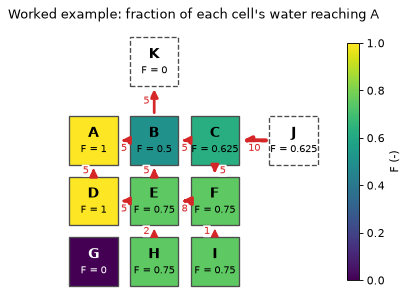

In [2]:
fb_step = helpers.fb13_step()
labels = list(helpers.FB13_LABELS)
destination_a = {"A": gs.select_cells(fb_step, [labels.index("A")])}
fb_net = gs.backward(fb_step, destination_a, NET)
F_fb = fb_net.fraction_through["A"]
print(f"{fb_step.n_cells} nodes, {len(helpers.FB13_EDGES)} edges; solver: {fb_net.solver_used[0]}")
print(f"water entering A: {fb_net.destination_inflow['A']:g} units")

helpers.draw_cell_graph(F_fb, title="Worked example: fraction of each cell's water reaching A")
plt.show()

**How to read the figure.** Each square is a cell coloured by its fraction through $F$; red arrows are the flows. J and K (dashed) lie outside the block.

- **B** sends 5 of its 10 units to A ($F = 1$) and 5 out of the block to K ($F = 0$), so $F_B = 0.5$.
- **E** sends 5 units to B ($F = 0.5$) and 5 to D, which drains entirely to A ($F = 1$): $F_E = (5 \times 0.5 + 5 \times 1)/10 = 0.75$.
- **C** receives 10 units from J and sends half to B and half to F ($F_F = F_E = 0.75$, since F drains only to E): $F_C = (5 \times 0.5 + 5 \times 0.75)/10 = 0.625$.
- **G** has no flow at all, so $F_G = 0$.

The table compares `gwsource` with the values published in Figs 5 to 8 of Foley and Black (2013): the fraction through $F_i$, the volume through $F_i T_i$ and the volume from $F_i \max(s_i, 0)$. The net sources inside the block are F, H and I. (Foley and Black (2013) print 0.7 for the volume from of I, rounded. One arrow label at C is ambiguous, but their text implies a throughflow of 10 in C, which is what J supplies here.)

In [3]:
published = pd.DataFrame(
    {
        "F": [1.0, 0.5, 0.625, 1.0, 0.75, 0.75, 0.0, 0.75, 0.75],
        "volume through": [10.0, 5.0, 6.25, 5.0, 7.5, 6.0, 0.0, 1.5, 0.75],
        "volume from": [0.0, 0.0, 0.0, 0.0, 0.0, 1.5, 0.0, 1.5, 0.75],
    },
    index=list("ABCDEFGHI"),
)  # Foley & Black (2013), Figs 5-8
computed = pd.DataFrame(
    {
        "F": F_fb[:9],
        "volume through": fb_net.volume_through["A"][:9],
        "volume from": fb_net.volume_from["A"][:9],
    },
    index=published.index,
)
table = pd.concat({"gwsource": computed, "published": published}, axis=1).swaplevel(axis=1)
display(table[["F", "volume through", "volume from"]].round(4))
assert np.allclose(computed.to_numpy(), published.to_numpy(), rtol=0.0, atol=1e-14)
print(f"water reaching A from J (outside the block): {fb_net.volume_from['A'][labels.index('J')]:g}")
print(f"volume from, all nodes: {fb_net.volume_from['A'].sum():g} = water entering A")

F           volume through           volume from          
  gwsource published       gwsource published    gwsource published
A    1.000     1.000          10.00     10.00        0.00      0.00
B    0.500     0.500           5.00      5.00        0.00      0.00
C    0.625     0.625           6.25      6.25        0.00      0.00
D    1.000     1.000           5.00      5.00        0.00      0.00
E    0.750     0.750           7.50      7.50        0.00      0.00
F    0.750     0.750           6.00      6.00        1.50      1.50
G    0.000     0.000           0.00      0.00        0.00      0.00
H    0.750     0.750           1.50      1.50        1.50      1.50
I    0.750     0.750           0.75      0.75        0.75      0.75

water reaching A from J (outside the block): 6.25
volume from, all nodes: 10 = water entering A


All values match the published ones to machine precision. Of the 10 units entering A, 6.25 come from J (through C) and 3.75 from the net sources F, H and I.

### The same numbers from an 11 × 11 matrix

To see that there is nothing more to it than a linear system, write the net-accounting equations as $T_i F_i - \sum_j q_{ij} F_j = 0$ for every node except A, set row A to $F_A = 1$, give the idle cell G the row $F_G = 0$, and solve with `numpy`:

In [4]:
src, dst, q = helpers.fb13_edge_arrays()
n = fb_step.n_cells
edge_in = np.bincount(dst, weights=q, minlength=n)
edge_out = np.bincount(src, weights=q, minlength=n)
throughflow = edge_in + np.maximum(edge_out - edge_in, 0.0)  # T_i

matrix = np.diag(throughflow)
matrix[src, dst] -= q  # T_i F_i - sum_j q_ij F_j
rhs = np.zeros(n)
fixed = np.zeros(n, dtype=bool)
fixed[labels.index("A")] = True  # destination: F = 1
idle = throughflow == 0.0  # no flow (G): F = 0
matrix[fixed | idle] = 0.0
matrix[fixed | idle, fixed | idle] = 1.0
rhs[fixed] = 1.0
display(pd.DataFrame(matrix, index=labels, columns=labels).astype(int).replace(0, ""))

F_by_hand = np.linalg.solve(matrix, rhs)
print("F by hand:", np.round(F_by_hand, 4))
assert np.allclose(F_by_hand, F_fb, rtol=0.0, atol=1e-14)

,A,B,C,D,E,F,G,H,I,J,K
A,1,,,,,,,,,,
B,-5,10,,,,,,,,,-5
C,,-5,10,,,-5,,,,,
D,-5,,,5,,,,,,,
E,,-5,,-5,10,,,,,,
F,,,,,-8,8,,,,,
G,,,,,,,1,,,,
H,,,,,-2,,,2,,,
I,,,,,,-1,,,1,,
J,,,-10,,,,,,,10,


F by hand: [1.    0.5   0.625 1.    0.75  0.75  0.    0.75  0.75  0.625 0.   ]


### Gross accounting gives the same answer here

`gwsource` defaults to **gross accounting**: every external term is kept as its own source or sink, and a destination is a set of sink *terms*, not of cells. To run the worked example with gross accounting, give it explicit terms: sources of 10 at J, 2 at F, 2 at H and 1 at I, and sinks of 10 at A and 5 at K (the net sources and sinks of the graph). The destination is the sink term in A.

In [5]:
fb_terms = helpers.fb13_step_with_terms(
    sources={"J": 10.0, "F": 2.0, "H": 2.0, "I": 1.0}, sinks={"A": 10.0, "K": 5.0}
)
sink_a = {"A": gs.select(fb_terms, package="SNK", cells=[labels.index("A")])}
fb_gross = gs.backward(fb_terms, sink_a, GROSS)
diff = np.abs(fb_gross.fraction_through["A"] - F_fb).max()
print(f"largest difference in F, gross vs net: {diff:.1e}")
print(f"volume from (gross): {fb_gross.volume_from['A'].sum():g} units, of which J {fb_gross.volume_from['A'][labels.index('J')]:g}")

largest difference in F, gross vs net: 0.0e+00
volume from (gross): 10 units, of which J 6.25


The two accountings agree because every sink in this example is **strong**: the sink in A takes all the water that enters A. So "fix $F_A = 1$" (net accounting) and "A's water leaves through its sink" (gross accounting) say the same thing. They part ways when a sink takes only part of the water flowing through its cell.

## 3. Gross vs net accounting on a weak sink

A sink is **weak** when its cell passes some of its water on to neighbours instead of sending all of it to the sink. Small wells in regional flow, partially penetrating wells in thick cells, drains and gaining river reaches in coarse layers are often weak sinks.

- **Net accounting** collapses the cell's terms into one net sink and fixes $F = 1$ in the destination cell: *all* the water passing through the cell is attributed to the sink, including the part that flows on.
- **Gross accounting** (the default) keeps the sink as its own term: the cell's water leaves through it in proportion to its flow, $d_i / O_i$, so a weak sink takes only its proportional share.

`hbd.build_layered` builds a three-layer version of the tutorial aquifer (horizontal K of 10, 1 and 15 m/d; vertical K a tenth of that). The supply well pumps 800 m³/d from layer 3, and a small well pumps 5 m³/d from layer 3 far upgradient, at row 17, column 13 (rows and columns counted from 1, from the north-west corner). `info["weak_well_node"]` is that well's cell.

In [6]:
run = hbd.build_layered(WORK / "layered", MF6)
step = gs.read_step(run.ws, boundnames=True)
weak_cell = run.info["weak_well_node"]
budget = gs.cell_budget(step)  # per-cell inflow and outflow totals
weak_layer, weak_row, weak_col = dict((name, cellid) for name, cellid, _ in run.info["wells"])["weak_well"]  # 0-based
print(f"grid {step.grid_type} {step.grid_shape}; weak well in layer {weak_layer + 1}, row {weak_row + 1}, "
      f"column {weak_col + 1} (node {weak_cell})")
print(f"water entering the weak well's cell: {budget.inflow[weak_cell]:6.2f} m3/d")
print(f"taken by the well:                   {budget.sink[weak_cell]:6.2f} m3/d")
print(f"passed on to neighbouring cells:     {budget.edge_out[weak_cell]:6.2f} m3/d")

grid DIS (3, 40, 40); weak well in layer 3, row 17, column 13 (node 3852)
water entering the weak well's cell:  33.67 m3/d
taken by the well:                     5.00 m3/d
passed on to neighbouring cells:      28.67 m3/d


The well's cell carries about 34 m³/d of regional flow and the well takes 5 of it: a weak sink. The supply well, by contrast, takes all the water entering its cell (a strong sink).

Trace both wells backward with both accountings. A selection holds both the terms (used by gross accounting) and the cells where the selected terms flow in the traced direction (used by net accounting). So the same groups serve both.

In [7]:
wells = {name: gs.select(step, boundnames=[name]) for name in WELLS}
gross = gs.backward(step, wells, GROSS)
net = gs.backward(step, wells, NET)

rows = {}
for name in WELLS:
    cell = run.info["well_nodes"][name]
    rows[name] = {
        "pumping (m3/d)": -step.term_flow[wells[name].terms].sum(),
        "cell throughflow (m3/d)": budget.outflow[cell],
        "F in well cell, gross": gross.fraction_through[name][cell],
        "F in well cell, net": net.fraction_through[name][cell],
        "water attributed, gross (m3/d)": gross.volume_from[name].sum(),
        "water attributed, net (m3/d)": net.volume_from[name].sum(),
    }
comparison = pd.DataFrame(rows).T
comparison["net / gross"] = (
    comparison["water attributed, net (m3/d)"] / comparison["water attributed, gross (m3/d)"]
)
display(comparison.round(3))

,pumping (m3/d),cell throughflow (m3/d),"F in well cell, gross","F in well cell, net","water attributed, gross (m3/d)","water attributed, net (m3/d)",net / gross
supply_well,800.0,800.000,1.000,1.0,800.0,800.000,1.000
weak_well,5.0,33.667,0.149,1.0,5.0,33.667,6.733


- **Supply well (strong sink):** both accountings give $F = 1$ in the well cell and attribute exactly the 800 m³/d pumped. Gross and net accounting agree, as in the worked example.
- **Weak well:** gross accounting gives the well $F = 5/33.667 \approx 0.149$ of its cell's water and attributes 5 m³/d to it, its pumping rate. Net accounting fixes $F = 1$ in the cell and attributes the cell's whole throughflow, 33.667 m³/d, 6.733 times what the well pumps. The "capture zone" of a 5 m³/d well becomes a strip of aquifer carrying 34 m³/d.

The maps show the fraction through of the weak well in the top layer (where recharge enters) and in layer 3 (the well's layer), net accounting on the left and gross accounting on the right, zoomed on the area upgradient of the well. The colour scale is logarithmic and the same in every panel; values below 0.001, including zero, take its lightest colour.

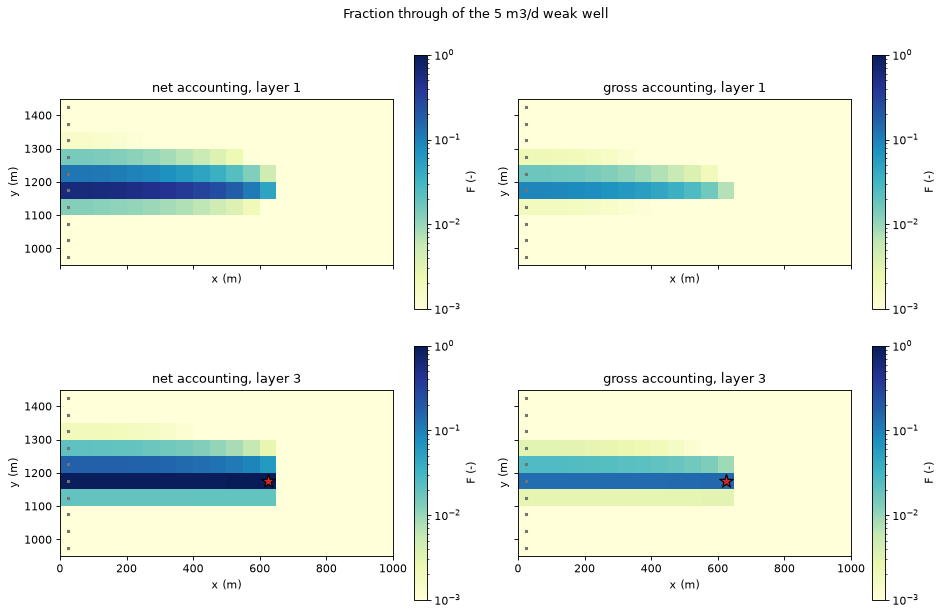

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12.0, 8.0), sharex=True, sharey=True)
for row, layer in enumerate(LAYERS):
    for col, (mode, res) in enumerate((("net", net), ("gross", gross))):
        ax = axes[row, col]
        hbd.plot_cells(
            run.grb_file, step, np.maximum(res.fraction_through["weak_well"], F_FLOOR), ax=ax,
            layer=layer, cmap="YlGnBu", norm=F_NORM, overlay=False, label="F (-)",
            title=f"{mode} accounting, layer {layer + 1}",
        )
        hbd.overlay_features(ax, run.grb_file, step, packages=("CHD", "WEL"), layer=layer,
                             legend=False)
        ax.set(**ZOOM)
fig.suptitle("Fraction through of the 5 m3/d weak well")
fig.tight_layout()
plt.show()

In [9]:
f_net = net.fraction_through["weak_well"]
f_gross = gross.fraction_through["weak_well"]
strip = f_net.reshape(step.grid_shape)[:, weak_row, :weak_col]  # the well's row, west of the well
for k, values in enumerate(strip):
    print(f"net F along row {weak_row + 1} west of the well, layer {k + 1}: {values.min():.2f} to {values.max():.2f}")
share = f_gross[weak_cell]
print(f"gross F in the weak well's cell: {share:.4f} = 5 / {budget.outflow[weak_cell]:.3f}")
print(f"gross F to the supply well in the same cell: {gross.fraction_through['supply_well'][weak_cell]:.3f}")
scaled = np.abs(f_gross - share * f_net).max()
print(f"largest |gross F - {share:.4f} x net F| over all cells: {scaled:.1e}")
assert scaled < 1e-10

net F along row 17 west of the well, layer 1: 0.11 to 0.61
net F along row 17 west of the well, layer 2: 0.70 to 0.93
net F along row 17 west of the well, layer 3: 0.93 to 0.99
gross F in the weak well's cell: 0.1485 = 5 / 33.667
gross F to the supply well in the same cell: 0.821
largest |gross F - 0.1485 x net F| over all cells: 2.3e-12


Both accountings find the same flow path: a narrow strip along row 17, from the constant-head west edge to the well, fed in layer 1 by recharge. They differ in how much of that water they give the well.

- With **net accounting**, everything that reaches the well's cell counts as captured. Along the strip west of the well, layer 3 sends 93 to 99 % of its water "to the well", and layer 2 sends 70 to 93 %. In layer 1 the share falls from 61 % at the west edge to 11 % one cell west of the well.
- With **gross accounting**, the fraction never exceeds the well's 0.149 share of its own cell. The other 85 % of the water passing through flows on. Most of it, 82 % of the cell's water, reaches the supply well further east.

Here the gross map is the net map multiplied by $5/33.667$, to round-off, because every path to the weak well passes through its cell. Where a destination has several cells, or a mixture of weak and strong sinks, the two maps also differ in shape.

**When to use net accounting.** Only to compare with studies that used the reference method (Foley and Black 2013), and for regression tests. It is never the default. When comparing, expect differences wherever a destination is a weak sink. They are a property of the accounting, not an error. With gross accounting the volume from always adds up to what the destination actually removes.

## 4. Diagnostics

### 4.1 Cell budget residual

MODFLOW 6 solves the flow equations to a tolerance, so each cell's inflow $I_i$ and outflow $O_i$ differ by a small **residual** $r_i = I_i - O_i$. MF6 writes it on the diagonal of FLOW-JA-FACE, and `gs.diagnostics.cell_residual` returns it. `gwsource` never forces it to zero. Backward fractions are normalised by outflow and forward fractions by inflow, so the residual cannot push a fraction outside [0, 1]. It only appears in the closure check below.

total |r|: 9.99e-07 m3/d of 67312 m3/d throughflow (relative 1.5e-11)
per cell: median |r| 1.2e-10, largest 1.2e-09 m3/d; median cell throughflow 9.2 m3/d


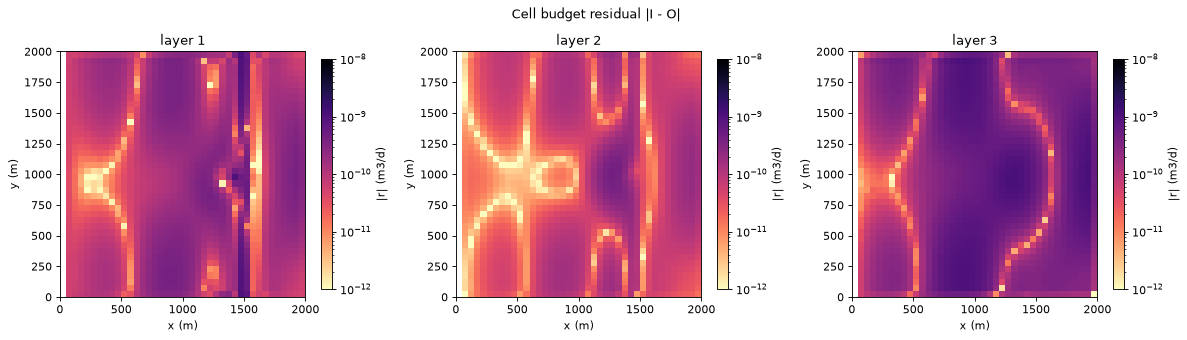

In [10]:
residual = gs.diagnostics.cell_residual(step)
error = gs.diagnostics.budget_error(step)
print(f"total |r|: {error['abs_residual']:.2e} m3/d of {error['throughflow']:.0f} m3/d throughflow "
      f"(relative {error['relative']:.1e})")
print(f"per cell: median |r| {np.median(np.abs(residual)):.1e}, largest {np.abs(residual).max():.1e} m3/d; "
      f"median cell throughflow {np.median(budget.outflow):.1f} m3/d")

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.2))
for layer, ax in enumerate(axes):
    hbd.plot_cells(
        run.grb_file, step, np.abs(residual), ax=ax, layer=layer, cmap="magma_r",
        norm=LogNorm(1e-12, 1e-8), overlay=False, label="|r| (m3/d)", title=f"layer {layer + 1}",
    )
fig.suptitle("Cell budget residual |I - O|")
fig.tight_layout()
plt.show()

The median residual is about $10^{-10}$ m³/d per cell, and the largest about $10^{-9}$ m³/d. The median cell throughflow is about 9 m³/d, so the residuals are roughly ten orders of magnitude smaller, as expected from the tight solver tolerances of the tutorial models. A loosely converged model shows larger values, often concentrated near wells, drying cells or boundaries; that is where to look first if a closure check fails.

### 4.2 Closure: the volume from adds up to the destination inflow

Summing the gross backward equations over all cells gives an exact identity (derivation in `gwsource.diagnostics`):

$$
\underbrace{\sum_i F_i\,\mathrm{Src}_i}_{\text{volume from}} \;-\; \underbrace{\sum_i F_i\, r_i}_{\text{residual term}} \;=\; \underbrace{\sum_{k \in D} |q_k|}_{\text{destination inflow}} .
$$

With the residual term it holds to round-off. Without it, the error is bounded by the model's total budget residual $\sum_i |r_i|$, since $0 \le F_i \le 1$. `gs.diagnostics.backward_closure` returns both sides.

In [11]:
rows = {}
for name in WELLS:
    check = gs.diagnostics.backward_closure(step, gross, name)
    rows[name] = {
        "volume from": check.lhs,
        "residual term": check.residual_term,
        "destination inflow": check.rhs,
        "error with residual term": check.error,
        "error without": check.error_without_residual,
    }
    assert check.relative_error < 1e-10
    assert abs(check.error_without_residual) <= error["abs_residual"] + 1e-10 * check.rhs
display(pd.DataFrame(rows).T.map(lambda v: f"{v:.6g}"))
print(f"bound on the error without the residual term, sum |r|: {error['abs_residual']:.1e} m3/d")

,volume from,residual term,destination inflow,error with residual term,error without
supply_well,800,-1.04284e-07,800,-2.27374e-13,-1.04284e-07
weak_well,5,-1.22617e-11,5,0,-1.22613e-11


bound on the error without the residual term, sum |r|: 1.0e-06 m3/d


Both wells close: with the residual term to round-off, and without it to well within the model's total residual. If a closure error without the residual term is large, the model's budget is the problem, not the trace. `backward_closure` also takes net-accounting results. There the residual term is zero and the volume from adds up to the net destination inflow: the destination cells' throughflow, less the water it would count twice because it passes from one destination cell to another or leaves the group and comes back (the throughflow sum itself is `destination_throughflow`). For a single well cell like the weak well, when no water leaves it and comes back, it is the cell's throughflow, which equals what the sink removes only for a strong sink (section 3).

### 4.3 A first look at duality

The flow from a set of sources $S$ to a destination $D$ can be computed two ways: **backward**, by weighting each source term by the fraction through of its cell, $\sum_{k \in S} F_{c(k)}\,q_k$; or **forward**, by tracing the sources and weighting each destination sink by the source fraction $G$ of its cell, $\sum_{k \in D} G_{c(k)}\,|q_k|$. Both give the same number, up to the residual term $\sum_i F_i G_i r_i$. Tutorial 03 uses forward mode in depth; here is the check for the supply well and each source package:

In [12]:
sources = {name: sel for name, sel in gs.groups_by_package(step).items()
           if (step.term_flow[sel.terms] > 0.0).any()}
fwd = gs.forward(step, sources, GROSS)
rows = {}
for name in sources:
    check = gs.diagnostics.duality(step, gross, "supply_well", fwd, name)
    rows[name] = {"backward (m3/d)": check.lhs, "forward (m3/d)": check.rhs,
                  "difference": check.error_without_residual, "residual term": check.residual_term}
    assert check.relative_error < 1e-10
display(pd.DataFrame(rows).T.map(lambda v: f"{v:.6g}"))
print(f"flow cycles: {len(gross.cycles)}; solver: {gross.solver_used[0]}")

,backward (m3/d),forward (m3/d),difference,residual term
RCH,419.783,419.783,-5.23403e-09,-5.23401e-09
CHD,380.217,380.217,-9.90502e-08,-9.90502e-08


flow cycles: 0; solver: topological


The supply well gets just over half its water from recharge and the rest from the constant-head west edge, and both directions agree to round-off. The model has no flow cycles, so the solver used the topological sweep; tutorial 04 shows the cycle report on a model that has them.

## 5. Boundary-control maps

Every drop of water in a cell with outflow leaves the model through *some* sink. Give every sink its own destination group and the fractions through must add up to 1 in every such cell:

$$
\sum_{g} F_{ig} = 1 \qquad \text{for every cell with } O_i > 0 .
$$

Each map then shows which boundary **controls** the water in each cell, and the sum is a strong check of the whole computation. Because the groups share one factorisation, the extra groups cost little. Below, one group per package that has sink terms: here the wells (`WEL`) and the river (`RIV`). Recharge and the constant heads only bring water in.

sink groups: WEL, RIV
sum of F over the groups, cells with outflow: min 0.999999999999999, max 1.000000000000001
layer 3 east of the river: F to WEL up to 0.91, above 0.5 in 133 cells
supply well water that entered east of the river: 67.9 m3/d
supply well water passing through the river column, by layer (m3/d): [  0.    0.4 294.5]


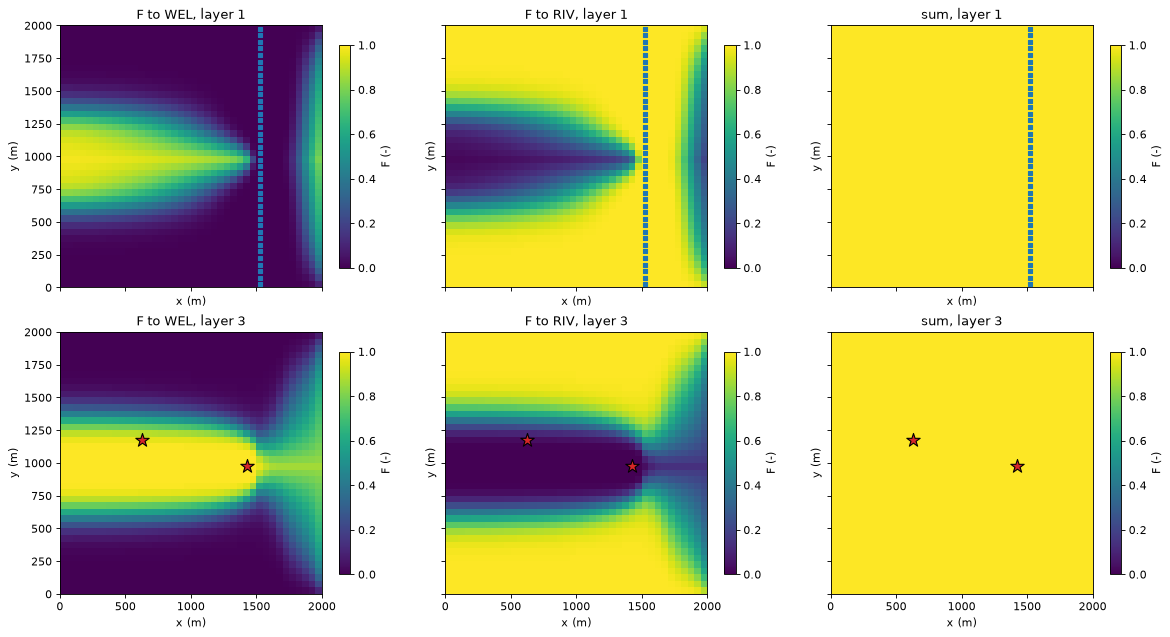

In [13]:
sinks = {name: sel for name, sel in gs.groups_by_package(step).items()
         if (step.term_flow[sel.terms] < 0.0).any()}
control = gs.backward(step, sinks, GROSS)
total = sum(control.fraction_through[name] for name in sinks)
draining = budget.outflow > 0.0
print("sink groups:", ", ".join(sinks))
print(f"sum of F over the groups, cells with outflow: min {total[draining].min():.15f}, "
      f"max {total[draining].max():.15f}")
assert np.allclose(total[draining], 1.0, rtol=0.0, atol=1e-12)
east = slice(run.spec.riv_col + 1, None)  # columns east of the river
f_wel = control.fraction_through["WEL"].reshape(step.grid_shape)
print(f"layer 3 east of the river: F to WEL up to {f_wel[2, :, east].max():.2f}, above 0.5 in {(f_wel[2, :, east] > 0.5).sum()} cells")
from_east = gross.volume_from["supply_well"].reshape(step.grid_shape)[:, :, east].sum()
print(f"supply well water that entered east of the river: {from_east:.1f} m3/d")
under = gross.volume_through["supply_well"].reshape(step.grid_shape)[:, :, run.spec.riv_col].sum(axis=1)
print("supply well water passing through the river column, by layer (m3/d):", np.round(under, 1))

panels = {**{f"F to {name}": control.fraction_through[name] for name in sinks}, "sum": total}
fig, axes = plt.subplots(len(LAYERS), len(panels), figsize=(5.0 * len(panels), 4.0 * len(LAYERS)),
                         sharex=True, sharey=True)
for row, layer in enumerate(LAYERS):
    for col, (title, values) in enumerate(panels.items()):
        ax = axes[row, col]
        hbd.plot_cells(
            run.grb_file, step, values, ax=ax, layer=layer, cmap="viridis", vmin=0.0, vmax=1.0,
            overlay=False, label="F (-)", title=f"{title}, layer {layer + 1}",
        )
        hbd.overlay_features(ax, run.grb_file, step, packages=("RIV", "WEL"), layer=layer,
                             legend=False)
fig.tight_layout()
plt.show()

Read each column as "where does the water in this cell leave the model?".

- **Layer 1:** a band through the middle of the model, from the west edge almost to the river, leaks down through the semi-confining layer 2 to the wells; north and south of it, the water stays shallow and drains to the river.
- **Layer 3:** the wells control a wider band, since the deep water is drawn towards the supply well's screen. East of the river, part of the water passes *under* the river in layer 3 and reaches the supply well. In this layered model the river is a weak sink that drains only part of the water flowing beneath it. Almost all of the supply well's water that passes through the river column does so in layer 3 (294.5 m³/d, against 0.4 m³/d in layer 2 and none in layer 1). Of the well's water, 67.9 m³/d fell as recharge east of the river.
- **Sum:** 1 everywhere: no water is lost or counted twice.

Groups can be as fine as needed. One group per sink *feature* (the two wells and the two river reaches, by boundname) also adds up to 1, and the **dominant sink** of each cell, the group with the largest fraction, is a compact boundary-control map:

cells dominated by each sink: {'river_north': 1753, 'river_south': 1656, 'supply_well': 1391, 'weak_well': 0}
cells east of the river dominated by the supply well: {'layer 1': 45, 'layer 3': 134}
weak well's fraction in its own cell: 0.149


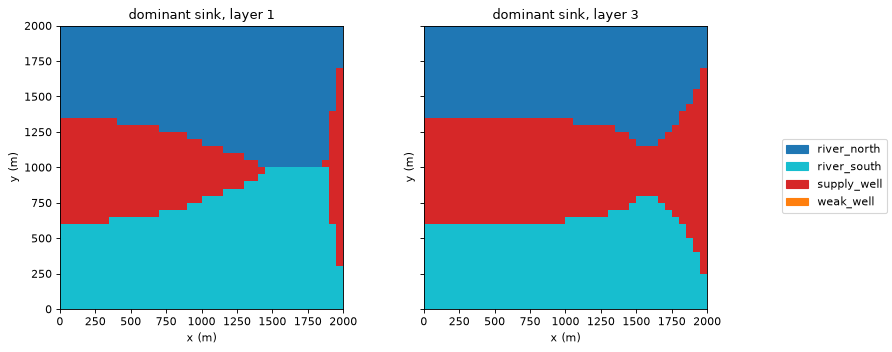

In [14]:
features = gs.groups_by_boundname(step)
by_feature = gs.backward(step, features, GROSS)
stack = np.column_stack([by_feature.fraction_through[name] for name in features])
assert np.allclose(stack.sum(axis=1)[draining], 1.0, rtol=0.0, atol=1e-12)
dominant = np.where(draining, stack.argmax(axis=1), np.nan)

counts = pd.Series(stack.argmax(axis=1)[draining], dtype=int).value_counts()
print("cells dominated by each sink:", {name: int(counts.get(i, 0)) for i, name in enumerate(features)})
supply_east = dominant.reshape(step.grid_shape)[:, :, east] == list(features).index("supply_well")
print("cells east of the river dominated by the supply well:",
      {f"layer {k + 1}": int(supply_east[k].sum()) for k in LAYERS})
print(f"weak well's fraction in its own cell: {by_feature.fraction_through['weak_well'][weak_cell]:.3f}")

colours = {"river_north": "tab:blue", "river_south": "tab:cyan", "supply_well": "tab:red",
           "weak_well": "tab:orange"}
cmap = ListedColormap([colours.get(name, "0.5") for name in features])
fig, axes = plt.subplots(1, len(LAYERS), figsize=(12.0, 4.6), sharey=True)
for ax, layer in zip(axes, LAYERS):
    hbd.plot_cells(run.grb_file, step, dominant, ax=ax, layer=layer, cmap=cmap, vmin=-0.5,
                   vmax=len(features) - 0.5, overlay=False, colorbar=False,
                   title=f"dominant sink, layer {layer + 1}")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(len(features))]
fig.legend(handles, list(features), loc="center right")
fig.subplots_adjust(right=0.82)
plt.show()

The supply well dominates a band from the west edge to the river in both layers. It also dominates an area east of the river, 45 cells in layer 1 and 134 in layer 3, whose water passes under the river. North and south of it the two river reaches take the water. The weak well dominates no cell at all. Even in its own cell it takes only 14.9 % of the water. That is the gross-accounting answer to "what does a 5 m³/d well capture?": 5 m³/d, spread thinly over the cells upstream of it.


In [15]:
print(f"runtime: {time.perf_counter() - START:.0f} s")

runtime: 2 s


## Key points

- **Full mixing** (each cell's outflows carry the same blend of its inflows) turns tracing into one sparse linear system, $(\mathbf I-\mathbf P)\mathbf F = \mathbf S\mathbf D$. Without flow cycles it is a single substitution sweep, the algorithm of Foley & Black (2013); with cycles it is solved exactly by sparse LU.
- `gs.from_edges` builds hand-made graphs. Net accounting reproduces the Foley & Black (2013) 3×3 worked example exactly.
- **Gross accounting** (default) keeps every external term separate, so a **weak sink** takes only its proportional share of its cell's water. **Net accounting** attributes the whole cell throughflow to it (here 6.733 times the pumping rate). Both agree for strong sinks. Use net accounting only to compare with the reference method (Foley and Black 2013).
- Check every trace: the **cell residual** (`cell_residual`, `budget_error`), the **closure** (`backward_closure`: exact with the residual term, within $\sum|r|$ without), and **duality** (`duality`). Closure and duality are identities of the method. They check the computation and the model budget, not the full-mixing assumption.
- **Boundary-control maps**: one group per sink package (or feature) gives fractions that sum to 1 in every cell with outflow.

## Next

[03 · Forward mode](../03_forward/03_forward.ipynb): what fraction of the water in each cell, and in the well, came from the river, from the regional inflow or from recharge on a chosen field; dilution ratios; and forward/backward duality in depth.